# Test neighborhood-level approach:

Note that the method below uses distances in latent space and so is not graph-based anymore

## Prep:

In [ ]:
!pip install nb_black

In [ ]:
!pip install scanpy

load modules:

In [ ]:
%load_ext nb_black

In [ ]:
import numpy as np
import scanpy as sc
import pandas as pd
import random
import os
from os.path import abspath
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.spatial.distance import cdist

set parameters and paths:

In [ ]:
sc.set_figure_params(dpi=200)

In [ ]:
plt.rcParams["figure.figsize"] = [15, 8]

In [ ]:
dir_res = abspath(
    os.path.join(os.getcwd(), os.pardir, "Results", "Neighborhood_based_HLCA")
)

path_hlca_ext = abspath(
    os.path.join(os.getcwd(), os.pardir, "Data", "HLCA_full_tranf.h5ad")
)

In [ ]:
Sheppard_healthy_unfiltered = f"{dir_res}/Sheppard_2020_Fibroblasts_Healthy/No_filter/"
Sheppard_healthy_filtered = f"{dir_res}/Sheppard_2020_Fibroblasts_Healthy/All_filter/"
Sheppard_healthy_props = (
    f"{dir_res}/Sheppard_2020_Fibroblasts_Healthy/proportion_tryout/"
)

Sheppard_IPF_unfiltered = f"{dir_res}/Sheppard_2020_Fibroblasts_IPF/No_filter/"
Sheppard_IPF_filtered = f"{dir_res}/Sheppard_2020_Fibroblasts_IPF/All_filter/"
# whole query+reference
Sheppard_healthy = f"{dir_res}/Sheppard_2020_Healthy/"
Sheppard_IPF = f"{dir_res}/Sheppard_2020_IPF/"
Sheppard_ScILD = f"{dir_res}/Sheppard_2020_ScILD/"
# Schiller 2020
Schiller_ELF = f"{dir_res}/Schiller_2020_Endstage_Lung_Fibrosis/"
Schiller_healthy = f"{dir_res}/Schiller_2020_Healthy/"
# Single Nucleus
Duong = f"{dir_res}/Duong_LungMAP/"
# Kaminski_2020
Kaminski_healthy = f"{dir_res}/Kaminski_2020_Healthy/"
Kaminski_IPF = f"{dir_res}/Kaminski_2020_IPF/"
Kaminski_COPD = f"{dir_res}/Kaminski_2020_COPD/"
# Meyer_2021
Meyer_3_prime = f"{dir_res}/Meyer_3_prime/"
Meyer_5_prime = f"{dir_res}/Meyer_5_prime/"
# Tata
Tata = f"{dir_res}/Tata/"

In [ ]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000]

helperfunctions:

In [ ]:
def load_stats(
    path,
    k_list=[50, 500, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000],
    prop=500,
    runs=20,
):
    list_results = []
    for k in k_list:
        n_list = []
        frac_list = []
        for i in range(0, runs):
            try:
                stats = pd.read_csv(f"{path}pvalues_{k}_{prop}_{i}.csv").dropna()
            except:
                continue
            if len(stats) < 1:
                continue
            n_significant = len(stats[stats.pvalue_corr < 0.05])
            n_list.append(n_significant)
            frac_list.append(n_significant / len(stats))
        if len(n_list) < 1:
            continue
        list_results.append(
            (k, np.mean(n_list), np.std(n_list), np.mean(frac_list), np.std(frac_list))
        )

    return pd.DataFrame(
        data=list_results,
        columns=["k", "n_significant", "std_significant", "fraction", "std_fraction"],
    )

In [ ]:
def load_stats_prop(
    path,
    k_list=[50, 500, 1000, 5000],
    prop_list=[10, 50, 100, 200, 500, 700, 1000, 1500, 2000],
    runs=10,
):
    list_results = []
    for k in k_list:
        n_list = []
        frac_list = []
        for p in prop_list:
            for i in range(0, runs):
                stats = pd.read_csv(f"{path}pvalues_{k}_{p}_{i}.csv").dropna()
                if len(stats) < 1:
                    continue
                n_significant = len(stats[stats.pvalue_corr < 0.05])
                n_list.append(n_significant)
                frac_list.append(n_significant / len(stats))
            if len(n_list) < 1:
                continue
            list_results.append(
                (
                    k,
                    p,
                    np.mean(n_list),
                    np.std(n_list),
                    np.mean(frac_list),
                    np.std(frac_list),
                )
            )

    return pd.DataFrame(
        data=list_results,
        columns=[
            "k",
            "prop",
            "n_significant",
            "std_significant",
            "fraction",
            "std_fraction",
        ],
    )

In [ ]:
def load_pvalues(path, k, p, i):
    try:
        return pd.read_csv(f"{path}pvalues_{k}_{p}_{i}.csv").dropna()
    except:
        print("No such data")
        return None

In [ ]:
def get_aggregation_per_cell_type(adata_ext_h, path_h, path_d, k, prop, runs):
    pvalues_celltype = []
    for r in range(runs):
        pvalues_h = load_pvalues(path_h, k, prop, r)
        pvalues_d = load_pvalues(path_d, k, prop, r)
        if pvalues_h is None or pvalues_d is None:
            print(f"skip run {r}")
            continue
        indices_h = pvalues_h["Unnamed: 0"]
        indices_d = pvalues_d["Unnamed: 0"]

        pvalues_h.index = indices_h
        pvalues_d.index = indices_d

        healthy_cts = adata_ext_h.obs.loc[indices_h, "cell_label"]
        disease_cts = adata_ext_h.obs.loc[indices_d, "cell_label"]

        for ct in healthy_cts.cat.categories:
            idx = healthy_cts[healthy_cts == ct].index.tolist()
            pvals = pvalues_h.loc[idx, "pvalue_corr"]
            pvalue = scipy.stats.combine_pvalues(pvals).pvalue
            pvalues_celltype.append((r, ct, "healthy", pvalue))

        for ct in disease_cts.cat.categories:
            idx = disease_cts[disease_cts == ct].index.tolist()
            pvals = pvalues_d.loc[idx, "pvalue_corr"]
            pvalue = scipy.stats.combine_pvalues(pvals).pvalue
            pvalues_celltype.append((r, ct, "disease", pvalue))

    pvalues_celltype = pd.DataFrame(
        pvalues_celltype, columns=["run", "cell_label", "condition", "p_value"]
    )

    # print(pvalues_celltype)

    return pvalues_celltype

In [ ]:
def visualize_nhood(subset_adata, distances, center_cell, k, dataset):
    # set annotations
    nearest_k = distances[1 : k + 1]
    subset_adata.obs[f"neighborhood_{center_cell}_{k}"] = np.nan
    subset_adata.obs.loc[
        subset_adata.obs.dataset == dataset, f"neighborhood_{center_cell}_{k}"
    ] = "Query"

    query_indices = subset_adata.obs[subset_adata.obs.dataset == dataset].index
    query_nearest_k = [cell for cell in nearest_k.index if cell in query_indices]

    subset_adata.obs.loc[
        nearest_k.index, f"neighborhood_{center_cell}_{k}"
    ] = "Included Reference"

    subset_adata.obs.loc[
        query_nearest_k, f"neighborhood_{center_cell}_{k}"
    ] = "Included Query"

    subset_adata.obs.loc[center_cell, f"neighborhood_{center_cell}_{k}"] = "Center"

    # get sample scores for k nearest distances

    grouped = (
        (
            subset_adata.obs.loc[nearest_k.index]
            .groupby("sample")
            .agg(
                {
                    f"distances_{center_cell}": "mean",
                    "core_or_extension": "first",
                    "ann_finest_level": "count",
                    "dataset": "first",
                }
            )
        )
        .dropna()
        .reset_index()
    )

    grouped = grouped[grouped["ann_finest_level"] >= 5]

    grouped["sample"] = grouped["sample"].cat.remove_unused_categories()
    grouped["dataset"] = grouped["dataset"].cat.remove_unused_categories()

    sns.boxplot(data=grouped, x="core_or_extension", y=f"distances_{center_cell}")
    sns.stripplot(
        data=grouped,
        x="core_or_extension",
        y=f"distances_{center_cell}",
        hue="dataset",
    )

    plt.title(f"neighborhood_{center_cell}_{k} distance per sample")
    plt.legend(bbox_to_anchor=[1, 0.75], loc="center left", fontsize=15)
    plt.show()

    # plot umap
    sc.pl.umap(
        subset_adata,
        color=f"neighborhood_{center_cell}_{k}",
        size=4,
        palette={
            "Center": "magenta",
            "Query": "skyblue",
            "Included Query": "red",
            "Included Reference": "purple",
        },
        title=f"{center_cell} neighborhood at k = {k}",
    )

### Comparison of Sheppard_2020 Healthy Fibroblasts to IPF Fibroblasts in two modes: filtered and unfiltered

#### Mode comparison


**filtered**: 
1. neighborhoods with less than three samples are excluded from calculation\
2. samples with less than 5 cells in a neighborhood are ignored\
**unfiltered**:\
only neighborhoods with either no query or no reference samples are ignored\

We want to see whether filtering makes a significant difference/ we filter out too much and results are unexpected.

#### Comparison of Healthy and IPF

As fibroblasts are shown to be severly affected by IPF we expect to see a higher fraction of significant neighborhoods in IPF fibroblasts than in healthy fibroblasts. We expect that because in a scenario of mapping disease+healthy on a fully healthy reference we expect healthy query to be mixing with healthy reference. We expect the disease query to mix less, as disease samples should be more similar to other disease samples (of the same disease) than to the healthy reference.

parameters:
- proportion of cells samples: 1/500
- runs for standard deviation: 20

In [ ]:
for name, path in [
    ("Healthy_unfiltered", Sheppard_healthy_unfiltered),
    ("Healthy_filtered", Sheppard_healthy_filtered),
    ("IPF_unfiltered", Sheppard_IPF_unfiltered),
    ("IPF_filtered", Sheppard_IPF_filtered),
]:
    stats = load_stats(path)
    plt.errorbar(
        x=stats.k, y=stats.fraction, yerr=stats.std_fraction, label=name, capsize=10
    )
plt.title(
    "Comparison of healthy and IPF fibroblasts in two different modes: filtered and unfiltered",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
plt.legend()

The two modes don't seem to make a significant difference, which favors the filtered version to reduce computational burden.


The difference between healthy and disease is significant from $k \approx 3000$ but the significance reduces with higher $k$.

### Comparison of different fractions of sampled center cells

Here we compare fractions of sampled center cell. We expect that more sampled center cells don't produce more significant hits, as the p-values are multiple testing corrected with the number of center cells.

parameters:
- runs for standard deviation: 10

In [ ]:
stats_prop = load_stats_prop(Sheppard_healthy_props)

In [ ]:
for k in [500, 1000, 5000]:
    stats = stats_prop[stats_prop.k == k]
    plt.errorbar(
        x=1 / stats.prop, y=stats.fraction, yerr=stats.std_fraction, label=k, capsize=10
    )
plt.legend()
plt.title(
    "Comparison of fraction of significant center cells in dependance of percentage of subsampled center cells",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("% of subsampled center cells", fontsize=20)
plt.legend()

plt.show()

for k in [500, 1000, 5000]:
    stats = stats_prop[stats_prop.k == k]
    plt.errorbar(
        x=(1 / stats.prop) * 100,
        y=stats.fraction,
        yerr=stats.std_fraction,
        label=k,
        capsize=10,
    )
plt.xscale("log")
plt.legend()

plt.title(
    "Comparison of fraction of significant center cells in dependance of percentage of subsampled center cells",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("% of subsampled center cells", fontsize=20)
plt.legend()

The fraction of significant neighborhoods goes down very slightly, but not very significantly with higher numbers of center cells. The choice of center cells is now limited by runtime and graph coverage but is not essential for the outcome. The standard deviation goes down, as with lower proportions the stocastic component of sampling is more prevalent. 

### Running the method on the whole healthy query + reference: comparing different k's

parameters:
- proportion of cells samples: 1/1000
- runs for standard deviation: 10

### Sheppard 2020

In [ ]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000, 200000]
prop = 1000
for name, path in [
    ("Healthy", Sheppard_healthy),
    ("IPF", Sheppard_IPF),
    ("ScILD", Sheppard_ScILD),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    plt.plot(
        stats.k, stats.fraction,label=name,
    )
plt.legend()
plt.title(
    "Sheppard: Comparison of healthy, Sclerodermal and IPF on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)


In [ ]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000, 200000]
prop = 1000
for name, path in [
    ("Healthy", Sheppard_healthy),
    ("IPF", Sheppard_IPF),
    ("ScILD", Sheppard_ScILD),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    plt.errorbar(
        x=stats.k, y=stats.fraction, yerr=stats.std_fraction, label=name, capsize=10
    )
plt.legend()
plt.title(
    "Sheppard: Comparison of healthy, Sclerodermal and IPF on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
plt.xticks(k_list, rotation=90)

### Schiller 2020

In [ ]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000]
prop = 1000
for name, path in [
    ("Healthy", Schiller_healthy),
    ("Endstage Lung Fibrosis", Schiller_ELF),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    plt.errorbar(
        x=stats.k, y=stats.fraction, yerr=stats.std_fraction, label=name, capsize=10
    )
plt.legend()
plt.title(
    "Schiller_2020: Comparison of healthy and fibrotic on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
plt.xticks(k_list, rotation=90)

### Schiller pvalue comparison (at n_hood = 10000)

In [ ]:
h["status"] = "healthy"
d["status"] = "disease"
hd = pd.merge(h, d, "outer")
hd["-log10(pvalue)"] = -np.log10(hd["pvalue_corr"])
sns.boxplot(data=hd, x="status", y="-log10(pvalue)")

### Schiller pvalue comparison (at n_hood = 8000)

In [ ]:
h["status"] = "healthy"
d["status"] = "disease"
hd = pd.merge(h, d, "outer")
hd["-log10(pvalue)"] = -np.log10(hd["pvalue_corr"])
sns.boxplot(data=hd, x="status", y="-log10(pvalue)")

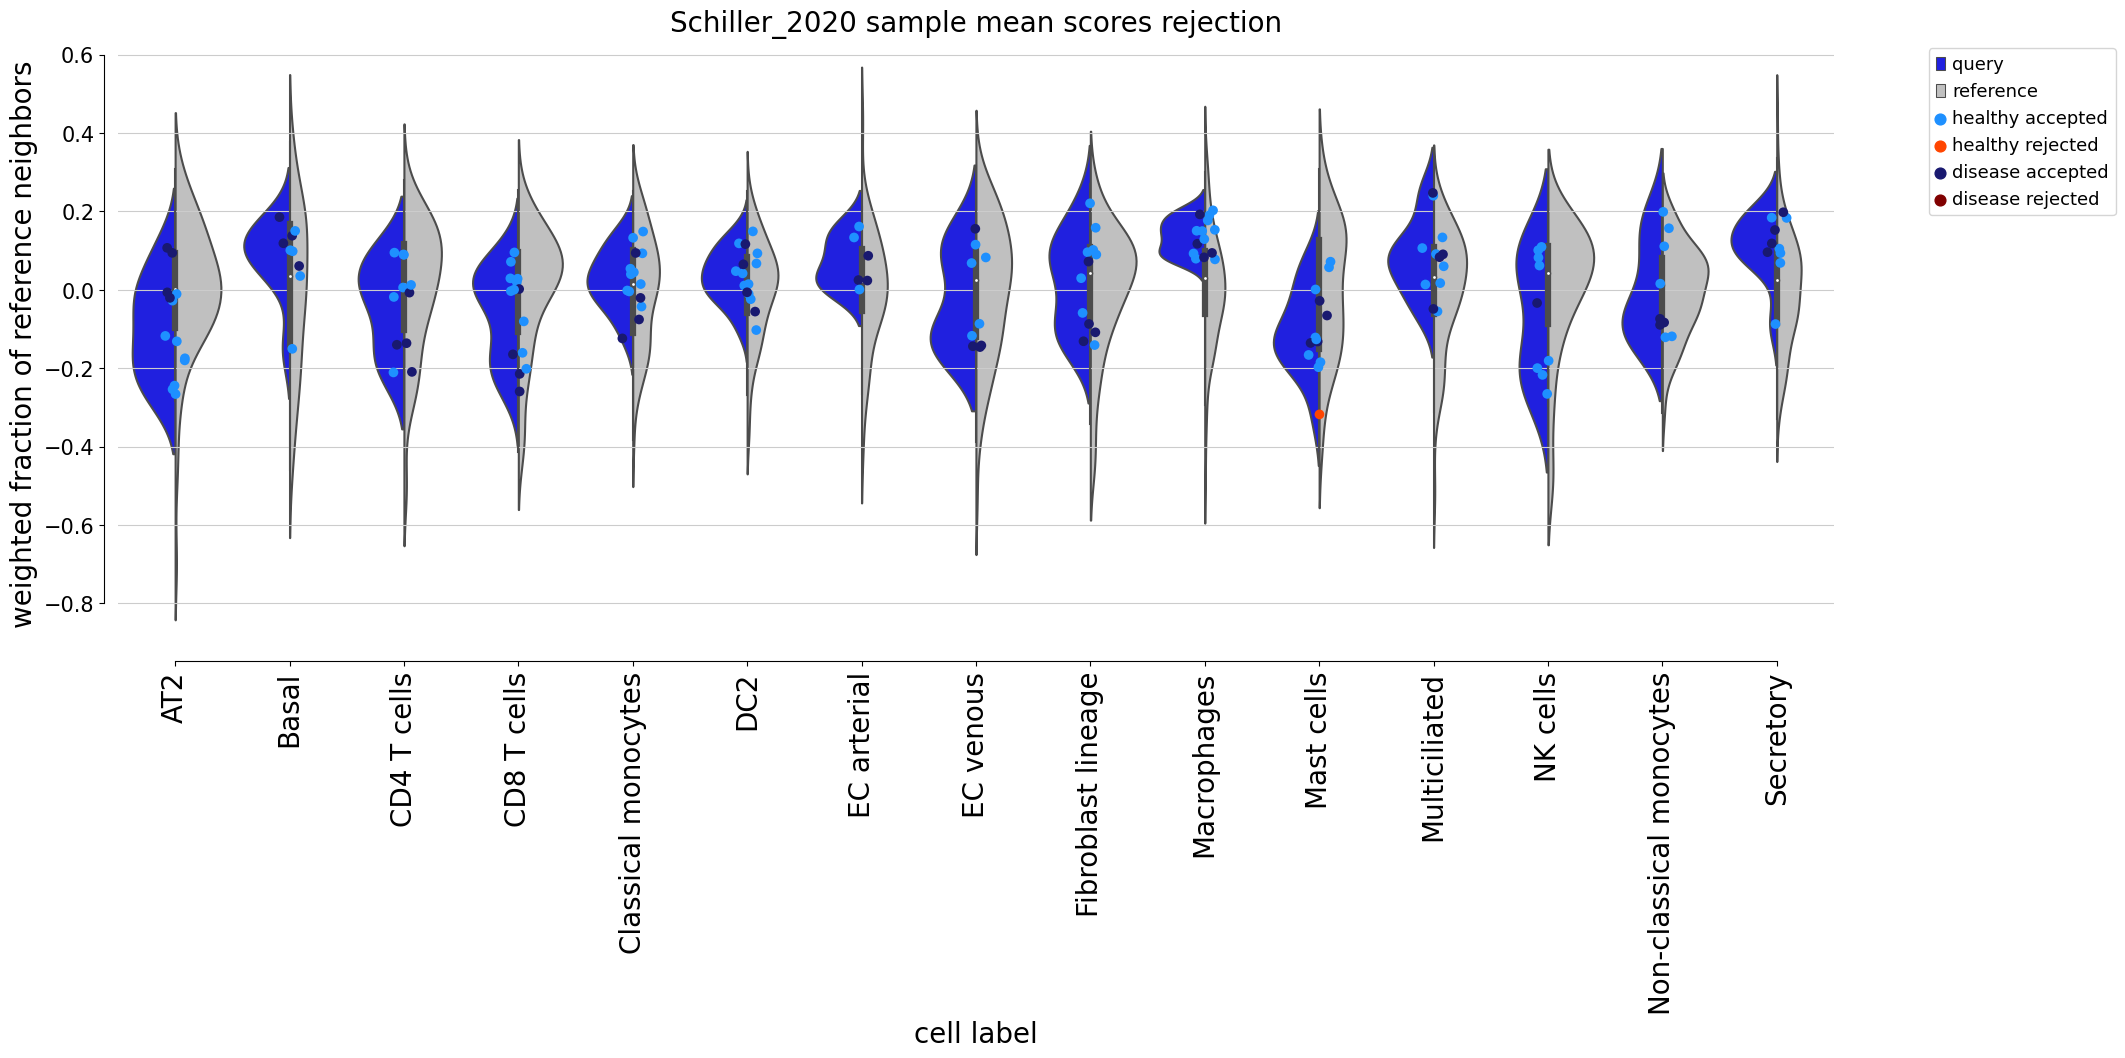

## All datasets full embedding comparison

In [ ]:
errorbars = False
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000]
prop = 1000
for name, path, color in [
    ("Single-nucleus", Duong, "dimgray"),
    ("Healthy_Kaminski", Kaminski_healthy, "violet"),
    ("IPF_Kaminski", Kaminski_IPF, "magenta"),
    ("COPD_Kaminski", Kaminski_COPD, "deeppink"),
    ("Meyer3", Meyer_3_prime, "lightgreen"),
    ("Meyer5", Meyer_5_prime, "darkgreen"),
    ("Tata", Tata, "sienna"),
    ("Healthy_Sheppard", Sheppard_healthy, "aqua"),
    ("IPF_Sheppard", Sheppard_IPF, "teal"),
    ("ScILD_Sheppard", Sheppard_ScILD, "darkslategray"),
    ("Healthy_Schiller", Schiller_healthy, "red"),
    ("Endstage Lung Fibrosis_Schiller", Schiller_ELF, "darkred"),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    if errorbars:
        plt.errorbar(
            x=stats.k,
            y=stats.fraction,
            yerr=stats.std_fraction,
            label=name,
            capsize=10,
            color=color,
        )
    else:
        plt.plot(stats.k, stats.fraction, label=name, color=color)
plt.legend(bbox_to_anchor=[1, 0.75], loc="center left")
plt.title(
    "Comparison of Healthy and Diseased on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
plt.xticks(k_list, rotation=90)
# plt.xlim(1000,30000)
plt.show()

# Tryout pvalue aggregation

In [ ]:
errorbars = True

prop = 1000
for name, path, color in [
    # ("Single-nucleus", Duong, "dimgray"),
    # ("Healthy_Kaminski", Kaminski_healthy, "violet"),
    # ("IPF_Kaminski", Kaminski_IPF, "magenta"),
    # ("COPD_Kaminski", Kaminski_COPD, "deeppink"),
    # ("Meyer3", Meyer_3_prime, "lightgreen"),
    # ("Meyer5", Meyer_5_prime, "darkgreen"),
    ("Tata", Tata, "sienna"),
    ("Healthy_Sheppard", Sheppard_healthy, "aqua"),
    ("IPF_Sheppard", Sheppard_IPF, "teal"),
    ("ScILD_Sheppard", Sheppard_ScILD, "darkslategray"),
    # ("Healthy_Schiller", Schiller_healthy, "red"),
    # ("Endstage Lung Fibrosis_Schiller", Schiller_ELF, "darkred"),
]:
    all_pvalues = []
    for k in k_list:
        pvalues_k = []
        for i in range(0, 10):
            try:
                pvalues = load_pvalues(path, k, 1000, i).pvalue_corr
                pvalue_comb = scipy.stats.combine_pvalues(pvalues)
                if pvalue_comb.pvalue <= 10 ** (-20):
                    pvalues_k.append(-np.log10(10 ** (-20)))
                else:
                    pvalues_k.append(-np.log10(pvalue_comb.pvalue))
            except:
                continue

        all_pvalues.append((k, np.mean(pvalues_k), np.std(pvalues_k)))
    all_pvalues = pd.DataFrame(data=all_pvalues, columns=["k", "mean", "std"])

    if errorbars:
        plt.errorbar(
            x=all_pvalues.k,
            y=all_pvalues["mean"],
            yerr=all_pvalues["std"],
            label=name,
            capsize=10,
            color=color,
        )
    else:
        plt.plot(all_pvalues.k, all_pvalues["mean"], label=name, color=color)


plt.legend(bbox_to_anchor=[1, 0.75], loc="center left")
plt.title(
    "Comparison of combined pvalues (scipy) on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("-log10 combined p-value", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
# plt.xticks(k_list, rotation=90)
# plt.xlim(1000,30000)
plt.plot(k_list, [-np.log10(0.05)] * len(k_list), color="red")
plt.show()

# Kaminski, Schiller and Sheppard: Further Exploration

## Sheppard: The good

In [ ]:
adata_ext_full = sc.read_h5ad(path_hlca_ext)

adata_ext_h = adata_ext_full[
    (adata_ext_full.obs.core_or_extension == "core")
    | (
        (adata_ext_full.obs.dataset == "Sheppard_2020")
        & ~(adata_ext_full.obs.lung_condition == "Systemic sclerosis-associated ILD")
    )
].copy()

In [ ]:
del adata_ext_full

In [ ]:
adata_ext_h.obs.lung_condition

In [ ]:
aggregated_ks = []
for k in k_list:
    aggr = get_aggregation_per_cell_type(
        adata_ext_h, Sheppard_healthy, Sheppard_IPF, k, 1000, 10
    )
    aggr["k"] = k
    aggregated_ks.append(aggr)

In [ ]:
aggr_ks = pd.concat(aggregated_ks, ignore_index=True)

In [ ]:
aggr_ks["-log10(p_value)"] = -np.log10(aggr_ks["p_value"])

In [ ]:
agg = aggr_ks.groupby(["cell_label", "condition", "k"]).agg({"p_value": "median"})
agg_sign = agg[agg.p_value < 0.05].sort_values(by="p_value")
print(agg_sign)
cell_types_sign = agg_sign.reset_index().cell_label.unique()

In [ ]:
cell_types_sign

In [ ]:
sns.lineplot(
    data=aggr_ks[
        (aggr_ks.cell_label.isin(cell_types_sign)) & (aggr_ks.condition == "healthy")
    ],
    x="k",
    y="-log10(p_value)",
    hue="cell_label",
)

plt.plot(k_list, [-np.log(0.05)] * len(k_list), color="white")

plt.legend(bbox_to_anchor=[1, 0.75], loc="center left", fontsize=15)
plt.ylim(0, 50)

plt.title(
    "Sheppard_2020 Healthy: p-value aggregation over cell types filtered (by median) significant cell types",
    size=20,
)

plt.ylabel("-log10(p-value)", size=20)
plt.xlabel("nhood size: k", size=20)

In [ ]:
sns.lineplot(
    data=aggr_ks[
        (aggr_ks.cell_label.isin(cell_types_sign)) & (aggr_ks.condition == "disease")
    ],
    x="k",
    y="-log10(p_value)",
    hue="cell_label",
)

plt.plot(k_list, [-np.log(0.05)] * len(k_list), color="white")


plt.legend(bbox_to_anchor=[1, 0.75], loc="center left", fontsize=15)
plt.ylim(0, 50)


plt.title(
    "Sheppard_2020 IPF: p-value aggregation over cell types filtered (by median) significant cell types",
    size=20,
)

plt.ylabel("-log10(p-value)", size=20)
plt.xlabel("nhood size: k", size=20)

## Time for Umaps!: Visualizing the neighborhoods

In [ ]:
#sc.pp.neighbors(adata_ext_h, 100)

In [ ]:
#sc.tl.umap(adata_ext_h)

In [ ]:
#umap = adata_ext_h.obsm["X_umap"]
#np.save(f"{Sheppard_healthy}/umap.npy", umap)

In [ ]:
adata_ext_h.obsm["X_umap"] = np.load(f"{Sheppard_healthy}/umap.npy")

In [ ]:
adata_ext_h.obs["query_health"] = np.nan
adata_ext_h.obs.loc[
    (adata_ext_h.obs.core_or_extension == "extension"), "query_health"
] = "Disease"
adata_ext_h.obs.loc[
    (adata_ext_h.obs.core_or_extension == "extension")
    & (adata_ext_h.obs.lung_condition == "Healthy"),
    "query_health",
] = "Healthy"

In [ ]:
sc.pl.umap(
    adata_ext_h,
    color="cell_label",
    size=5,
)

In [ ]:
sc.pl.umap(
    adata_ext_h,
    color="query_health",
    size=2,
    palette={"Disease": "salmon", "Healthy": "cornflowerblue"},
)

In [ ]:
h = load_pvalues(Sheppard_healthy, 10000, 1000, 6)

In [ ]:
d = load_pvalues(Sheppard_IPF, 10000, 1000, 6)

In [ ]:
h.sort_values(by="pvalue_corr")[0:10]

In [ ]:
d.sort_values(by="pvalue_corr")[:10]

In [ ]:
adata_ext_h.obs["sampled_significant"] = np.nan

In [ ]:
adata_ext_h.obs.loc[h["Unnamed: 0"], "sampled_significant"] = "Sampled healthy"
adata_ext_h.obs.loc[
    h.loc[h["pvalue_corr"] < 0.05, "Unnamed: 0"], "sampled_significant"
] = "Significant healthy"

adata_ext_h.obs.loc[
    h.loc[h["pvalue_corr"] < 0.001, "Unnamed: 0"], "sampled_significant"
] = "Very Significant healthy"

In [ ]:
adata_ext_h.obs.loc[d["Unnamed: 0"], "sampled_significant"] = "Sampled disease"
adata_ext_h.obs.loc[
    d.loc[d["pvalue_corr"] < 0.05, "Unnamed: 0"], "sampled_significant"
] = "Significant disease"

adata_ext_h.obs.loc[
    d.loc[d["pvalue_corr"] < 0.001, "Unnamed: 0"], "sampled_significant"
] = "Very Significant disease"




In [ ]:
adata_ext_h.obs.loc[
    "GGGTTGCTCCGCGTTT-1-HCATisStab7659970", "sampled_significant"
] = "sampled for analysis (r)"

adata_ext_h.obs.loc[
    "CATGCCTGTCTTGATG_NML3_tsukui", "sampled_significant"
] = "sampled for analysis (q)"



In [ ]:
sc.pl.umap(
    adata_ext_h,
    color="sampled_significant",
    size=50,
    palette={
        "Sampled disease": "salmon",
        "Significant disease": "darkred",
        "Sampled healthy": "cornflowerblue",
        "Significant healthy": "darkslateblue",
        "Very Significant disease": "red",
        "Very Significant healthy": "blue",
        "sampled for analysis (q)": "magenta",
        "sampled for analysis (r)": "lime",
    },
)

## Significant neighborhoods in Sheppard Healthy: visualization

We look at **CATGCCTGTCTTGATG_NML3_tsukui** (query) and **GGGTTGCTCCGCGTTT-1-HCATisStab7659970** (reference)  more closely at different k sizes for healthy query!

In [ ]:
query_center = "CATGCCTGTCTTGATG_NML3_tsukui"  # pvalue corr = 0.000037
reference_center = "GGGTTGCTCCGCGTTT-1-HCATisStab7659970"  # pvalue_corr = 0.000043

### Query Center

In [ ]:
subset_adata = adata_ext_h[adata_ext_h.obs.lung_condition == "Healthy"].copy()

In [ ]:
distances = cdist(adata_ext_h[query_center, :].X, subset_adata.X).flatten()

In [ ]:
subset_adata.obs[f"distances_{query_center}"] = distances

In [ ]:
distances = subset_adata.obs[f"distances_{query_center}"].sort_values()

In [ ]:
dist_plot = distances[0:100000].to_numpy()

In [ ]:
plt.plot(dist_plot)
plt.xticks(k_list, rotation=90)
plt.show()

In [ ]:
for k in k_list:
    visualize_nhood(subset_adata, distances, query_center, k, "Sheppard_2020")

### Reference Center

In [ ]:
distances = cdist(adata_ext_h[reference_center, :].X, subset_adata.X).flatten()

In [ ]:
subset_adata.obs[f"distances_{reference_center}"] = distances

In [ ]:
distances = subset_adata.obs[f"distances_{reference_center}"].sort_values()

In [ ]:
dist_plot = distances[0:100000].to_numpy()

plt.plot(dist_plot)
plt.xticks(k_list, rotation=90)
plt.show()

In [ ]:
for k in k_list:
    visualize_nhood(subset_adata, distances, reference_center, k, "Sheppard_2020")

## Non-significant neighborhoods: Sheppard Healthy

Now lets look at two not significant neighborhoods at k = 10000. Note: that doesn't mean it isn't significant in other k's

In [ ]:
subset_adata = adata_ext_h[adata_ext_h.obs.lung_condition == "Healthy"].copy()

In [ ]:
query_indices = subset_adata.obs[subset_adata.obs.dataset == "Sheppard_2020"].index

In [ ]:
h = load_pvalues(Sheppard_healthy, 10000, 1000, 6)
h.sort_values("pvalue_corr",ascending=False)


In [ ]:
adata_ext_h.obs["sampled_significant"] = np.nan

adata_ext_h.obs.loc[h["Unnamed: 0"], "sampled_significant"] = "Sampled healthy"
adata_ext_h.obs.loc[
    h.loc[h["pvalue_corr"] < 0.05, "Unnamed: 0"], "sampled_significant"
] = "Significant healthy"

adata_ext_h.obs.loc[
    h.loc[h["pvalue_corr"] < 0.001, "Unnamed: 0"], "sampled_significant"
] = "Very Significant healthy"

adata_ext_h.obs.loc[d["Unnamed: 0"], "sampled_significant"] = "Sampled disease"
adata_ext_h.obs.loc[
    d.loc[d["pvalue_corr"] < 0.05, "Unnamed: 0"], "sampled_significant"
] = "Significant disease"

adata_ext_h.obs.loc[
    d.loc[d["pvalue_corr"] < 0.001, "Unnamed: 0"], "sampled_significant"
] = "Very Significant disease"


In [ ]:
adata_ext_h.obs.loc[
    "ACGCCGACACCTTGTC_SC20", "sampled_significant"
] = "sampled for analysis (r)"

adata_ext_h.obs.loc[
    "TAAGAGAAGCCACCTG_NML2_tsukui", "sampled_significant"
] = "sampled for analysis (q)"



In [ ]:
sc.pl.umap(
    adata_ext_h,
    color="sampled_significant",
    size=50,
    palette={
        "Sampled disease": "salmon",
        "Significant disease": "darkred",
        "Sampled healthy": "cornflowerblue",
        "Significant healthy": "darkslateblue",
        "Very Significant disease": "red",
        "Very Significant healthy": "blue",
        "sampled for analysis (q)": "magenta",
        "sampled for analysis (r)": "lime",
    },
)

Intestingly the sampled reference center cell is right next to an significant cell on the umap

In [ ]:
query_center = "TAAGAGAAGCCACCTG_NML2_tsukui"
reference_center = "ACGCCGACACCTTGTC_SC20"

### Query center

In [ ]:
distances = cdist(adata_ext_h[query_center, :].X, subset_adata.X).flatten()

In [ ]:
subset_adata.obs[f"distances_{query_center}"] = distances

In [ ]:
distances = subset_adata.obs[f"distances_{query_center}"].sort_values()

In [ ]:
dist_plot = distances[0:100000].to_numpy()

In [ ]:
plt.plot(dist_plot)
plt.xticks(k_list, rotation=90)
plt.show()

In [ ]:
for k in k_list:
    visualize_nhood(subset_adata, distances, query_center, k, "Sheppard_2020")

### Reference center

In [ ]:
distances = cdist(adata_ext_h[reference_center, :].X, subset_adata.X).flatten()

In [ ]:
subset_adata.obs[f"distances_{reference_center}"] = distances

In [ ]:
distances = subset_adata.obs[f"distances_{reference_center}"].sort_values()

In [ ]:
dist_plot = distances[0:100000].to_numpy()

In [ ]:
plt.plot(dist_plot)
plt.xticks(k_list, rotation=90)
plt.show()

In [ ]:
for k in k_list:
    visualize_nhood(subset_adata, distances, reference_center, k, "Sheppard_2020")